# Лекция 12. Разреженные матрицы в крупномасштабных вычислениях

В лекции 11 мы решали плотные СЛАУ и в самом конце встретили матрицу, у
которой из $n^2$ элементов ненулевых лишь $3n-2$: трёхдиагональную матрицу
сеточной задачи. Прогонка решала её за $\sim 5n$ операций вместо $n^3/3$
именно потому, что умела **не трогать нули**. На крупных задачах — уравнения
математической физики, электрические сети, графы, оптимизация — матрицы
состоят из нулей почти целиком, и нули эти не случайны: они повторяют
структуру самой задачи. Сегодня — как с этим работают крупные вычисления:

1. **откуда берётся разреженность**: сетки, графы и цена «плотного» подхода;
2. **форматы сжатого хранения**: COO, CSR, CSC — и операция SpMV;
3. **sparse direct solvers**: Гаусс, который умеет пропускать нули;
4. **fill-in**: лавинообразное заполнение нулей при исключении;
5. **переупорядочивания**: RCM, AMD и вложенные сечения (Nested Dissection) —
   порядок исключения как самостоятельный ресурс;
6. итоги: сводная таблица сложности и что дальше.

> ❓ **Вопрос лекции.** Пусть в матрице $10^6 \times 10^6$ в каждой строке
> ненулевых всего $\sim 5$ — заполнено 0,0005 %. Почему «лобовой» метод
> Гаусса потребует для неё **терабайты** памяти, а правильный порядок
> исключения уложится в **сотни мегабайт**? Что именно превращает
> невозможную задачу в рутинную?

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import reverse_cuthill_mckee

np.set_printoptions(linewidth=120, precision=4, suppress=True)

print('окружение лекции 12:')
print('  numpy', np.__version__, '| scipy', scipy.__version__)
print('  scipy.sparse: форматы coo/csr/csc/lil/dia, решатель splu, графовый модуль csgraph')

окружение лекции 12:
  numpy 1.26.4 | scipy 1.17.1
  scipy.sparse: форматы coo/csr/csc/lil/dia, решатель splu, графовый модуль csgraph

## 1. 🎯 Откуда берётся разреженность: сетки и графы

Типовой источник крупных СЛАУ — **дискретизация** дифференциальных уравнений
(лекция 11 закончилась именно такой задачей). Берём расчётную сетку, в каждом
узле — неизвестное (температура, давление, потенциал), а уравнение каждого
узла связывает его лишь с **несколькими соседями**: шаблон разностной схемы
маленький, а матрица гигантская.

- одномерная сетка, трёхточечный шаблон $u_{i-1},\,u_i,\,u_{i+1}$ —
  **трёхдиагональная** матрица (наша прогонка — уже работа с разреженностью);
- двумерная сетка, пятиточечный шаблон — «лента с дырками»: уравнение узла
  $(i, j)$ связывает его с $(i \pm 1, j)$ и $(i, j \pm 1)$, но не с
  диагональными соседями.

Такая матрица — это на самом деле **граф**: узел сетки ↔ вершина графа,
ненулевой элемент $a_{ij} \neq 0$ ↔ ребро $i \leftrightarrow j$. Вся
разреженная алгебра ниже — разговор на языке этого графа: хранение — список
рёбер, умножение на вектор — обход соседей, факторизация — последовательное
исключение вершин.

сравнение заполненности:
  1D, n =  12:   элементов   144, ненулевых  34  (24% матрицы)
  2D, n = 144:  элементов  20736, ненулевых  672  (3.2% матрицы)

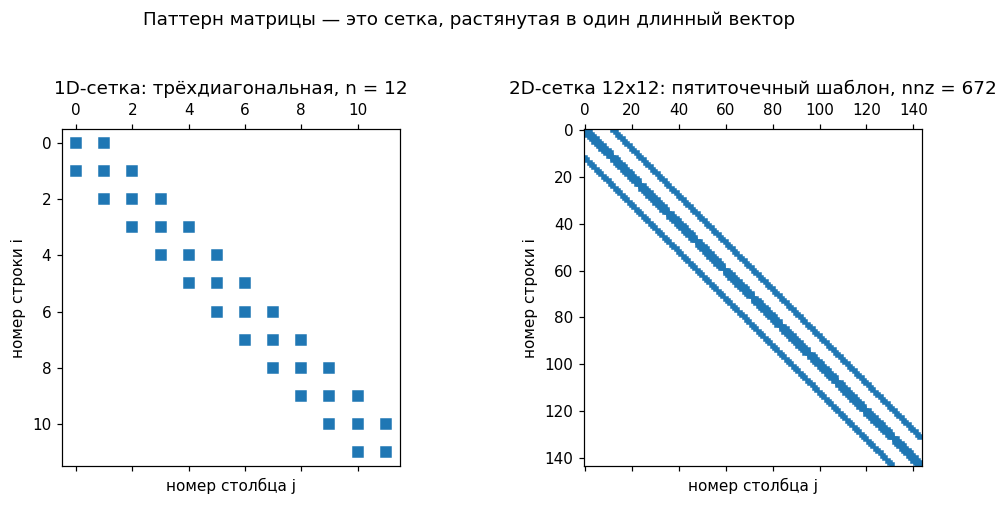

In [2]:
# --- 1D: отрезок с n внутренними узлами, трёхточечный шаблон ---
n = 12
A1 = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)   # трёхдиагональная (масштаб h^-2 опустим)


# --- 2D: сетка m x m, пятиточечный шаблон, натуральный порядок «строка за строкой» ---
def grid_laplacian(m):
    """Матрица 2D-лапласиана на сетке m x m; узлу (i, j) отвечает номер i*m + j."""
    T = sp.diags([np.ones(m - 1), -2 * np.ones(m), np.ones(m - 1)], [-1, 0, 1],
                 shape=(m, m))
    return (sp.kron(sp.eye(m), T) + sp.kron(T, sp.eye(m))).tocsr()


m = 12
A2 = grid_laplacian(m)

print('сравнение заполненности:')
print(f'  1D, n = {n:3d}:   элементов {n ** 2:5d}, ненулевых {(A1 != 0).sum():3d}'
      f'  ({(A1 != 0).sum() / n ** 2:.0%} матрицы)')
print(f'  2D, n = {m * m:3d}:  элементов {m ** 4:6d}, ненулевых {A2.nnz:4d}'
      f'  ({A2.nnz / m ** 4:.1%} матрицы)')

fig, ax = plt.subplots(1, 2, figsize=(9.6, 4.4))
ax[0].spy(A1, markersize=6, color='tab:blue')
ax[0].set_title(f'1D-сетка: трёхдиагональная, n = {n}')
ax[1].spy(A2, markersize=2.5, color='tab:blue')
ax[1].set_title(f'2D-сетка {m}x{m}: пятиточечный шаблон, nnz = {A2.nnz}')
for a in ax:
    a.set_xlabel('номер столбца j')
    a.set_ylabel('номер строки i')
fig.suptitle('Паттерн матрицы — это сетка, растянутая в один длинный вектор', y=1.03)
fig.tight_layout()

### 1.1 Цена «плотного» подхода

Плотная арифметика хранит все $n^2$ элементов — даже нули, даже если их
99,99 %. Считаем в байтах (float64 для значений, int32 для индексов):

- плотная матрица: $8\,n^2$ байт. Для $n = 10^6$ (сетка всего
  $1000 \times 1000$) это $8$ ТБ — не влезает ни в один персональный
  компьютер, даже если выбросить всё остальное;
- CSR-хранение (форматы — в §2): $\approx 12\cdot \mathrm{nnz}$ байт; при
  $\mathrm{nnz} \approx 5n$ — около $60$ МБ.

Разница — в $\sim 10^5$ раз, и она только растёт с $n$: память плотной
матрицы $O(n^2)$, разреженной — $O(n)$, то есть **линейная** по размеру
задачи. Крупномасштабные вычисления без сжатого хранения невозможны в
принципе.

In [3]:
# --- память: плотная матрица против CSR ---
def csr_bytes(nnz, n):
    """Байты CSR: data (float64) + indices (int32) + indptr (int32)."""
    return 8 * nnz + 4 * nnz + 4 * (n + 1)


print(f'{"сетка":>10} {"n":>9} {"nnz~5n":>10} {"плотная":>9} {"CSR":>10} {"экономия":>9}')
for m in (100, 500, 1000, 2000, 5000):
    n = m * m
    nnz = 5 * n                     # ~5 ненулевых на строку у пятиточечного шаблона
    dense = 8 * n * n
    csr = csr_bytes(nnz, n)
    print(f'{m:>4}x{m:<5} {n:>9} {nnz:>10} {dense / 2**40:>7.2f} ТБ'
          f' {csr / 2**20:>8.1f} МиБ {dense / csr:>8.0f}x')

n = 10 ** 6
print()
print(f'итог для сетки 1000 x 1000 (n = {n}):')
print(f'  плотная матрица: {8 * n ** 2 / 2**40:5.1f} ТиБ — нужен суперкомпьютер и много терпения,')
print(f'  CSR:             {csr_bytes(5 * n, n) / 2**20:5.1f} МиБ — помещается в браузерную вкладку.')

     сетка         n     nnz~5n   плотная        CSR  экономия
 100x100       10000      50000    0.00 ТБ      0.6 МиБ     1250x
 500x500      250000    1250000    0.45 ТБ     15.3 МиБ    31250x
1000x1000    1000000    5000000    7.28 ТБ     61.0 МиБ   125000x
2000x2000    4000000   20000000  116.42 ТБ    244.1 МиБ   500000x
5000x5000   25000000  125000000 4547.47 ТБ   1525.9 МиБ  3125000x

итог для сетки 1000 x 1000 (n = 1000000):
  плотная матрица:   7.3 ТиБ — нужен суперкомпьютер и много терпения,
  CSR:              61.0 МиБ — помещается в браузерную вкладку.

## 2. 📦 Форматы сжатого хранения: COO, CSR, CSC

Идея одна — **хранить только ненулевые**, но с адресами, по которым их можно
быстро находить. Три канонических формата.

**COO (coordinate)** — «список почтовых адресов»: три массива длины
$\mathrm{nnz}$ — `data` (значения), `row` и `col` (координаты). Просто и
надёжно; элементы можно добавлять в любом порядке и даже с повторами — при
конверсии повторяющиеся координаты **суммируются** (так собирают матрицы в
МКЭ: в один узел «вкладываются» несколько элементов сетки). Минус: искать
«строку $i$» приходится перебором.

**CSR (compressed sparse row)** — сжатие по строкам: значения и столбцовые
индексы лежат в массивах `data` и `indices`, а `indptr` длины $n+1$ хранит,
где начинается каждая строка: строка $i$ — это срез
`[indptr[i]:indptr[i+1]]`. Память: $8\,\mathrm{nnz} + 4\,\mathrm{nnz} +
4\,(n+1)$ байт. Зато умножение на вектор — один проход по `data`.
**CSR — главный рабочий формат** разреженной алгебры.

**CSC (compressed sparse column)** — зеркальный CSR по столбцам. Незаменим,
когда логика задачи движется по столбцам: извлечение столбцов, сборка
«вкладов», работа прямых решателей (факторизация идёт по столбцам).

(Есть и другие: `lil` — удобно менять поэлементно, `dia` — ленточные,
`bsr` — блочные; сегодня работают первые три.)

In [4]:
A = np.array([[1., 0., 2., 0.],
              [0., 0., 3., 4.],
              [5., 0., 0., 0.],
              [0., 6., 0., 7.]])

print('плотная матрица A (7 ненулевых из 16):')
print(A)
print()
coo = sp.coo_matrix(A)
print('COO  (data, row, col — тройки-«адреса», как пришли):')
print('  data =', coo.data, '| row =', coo.row, '| col =', coo.col)
csr = coo.tocsr()
print()
print('CSR  (indptr — границы строк, indices — столбцы, data — значения):')
print('  indptr  =', csr.indptr, '   строка i = срез [indptr[i]:indptr[i+1]]')
print('  indices =', csr.indices)
print('  data    =', csr.data)
csc = coo.tocsc()
print()
print('CSC  (то же самое, но столбцами):')
print('  indptr  =', csc.indptr, '   столбец j = срез [indptr[j]:indptr[j+1]]')
print('  indices =', csc.indices)
print('  data    =', csc.data)
print()
print('проверка: csr.toarray() == A ?', np.array_equal(csr.toarray(), A),
      '| nnz =', csr.nnz)

# --- дубликаты в COO суммируются при конверсии: так собирают матрицы «вкладами» ---
r = np.array([0, 1, 0])
c = np.array([0, 1, 0])
v = np.array([2., 3., 5.])
D = sp.coo_matrix((v, (r, c)), shape=(2, 2)).tocsr()
print()
print('дубликаты: координата (0, 0) встречается дважды, со значениями 2 и 5:')
print(D.toarray(), ' <- вклады сложились')

плотная матрица A (7 ненулевых из 16):
[[1. 0. 2. 0.]
 [0. 0. 3. 4.]
 [5. 0. 0. 0.]
 [0. 6. 0. 7.]]

COO  (data, row, col — тройки-«адреса», как пришли):
  data = [1. 2. 3. 4. 5. 6. 7.] | row = [0 0 1 1 2 3 3] | col = [0 2 2 3 0 1 3]

CSR  (indptr — границы строк, indices — столбцы, data — значения):
  indptr  = [0 2 4 5 7]    строка i = срез [indptr[i]:indptr[i+1]]
  indices = [0 2 2 3 0 1 3]
  data    = [1. 2. 3. 4. 5. 6. 7.]

CSC  (то же самое, но столбцами):
  indptr  = [0 2 3 5 7]    столбец j = срез [indptr[j]:indptr[j+1]]
  indices = [0 2 3 0 1 1 3]
  data    = [1. 5. 6. 2. 3. 4. 7.]

проверка: csr.toarray() == A ? True | nnz = 7

дубликаты: координата (0, 0) встречается дважды, со значениями 2 и 5:
[[7. 0.]
 [0. 3.]]  <- вклады сложились

### 2.1 SpMV: главная операция разреженной алгебры

Умножение $y = Ax$ — «рабочий ход» всей итеративной линейной алгебры (и мы
будем мерить им скорость методов в следующих лекциях). Для матрицы в CSR это
один проход по ненулевым:

$$y_i \;=\; \sum_{k=\mathrm{indptr}[i]}^{\mathrm{indptr}[i+1]-1}
\mathrm{data}[k]\cdot x_{\mathrm{indices}[k]}$$

— $O(\mathrm{nnz})$ вместо $O(n^2)$, и нули физически не читаются из памяти.
Посмотрим, что это даёт на практике.

In [5]:
# --- SpMV против плотного matvec на сетке 64 x 64 ---
m = 64
n = m * m                                  # 4096 неизвестных
A = grid_laplacian(m)
Ad = A.toarray()                           # плотный дубликат той же матрицы
x = np.random.default_rng(0).random(n)

t0 = time.perf_counter()
for _ in range(30):
    yd = Ad @ x
t_dense = (time.perf_counter() - t0) / 30

t0 = time.perf_counter()
for _ in range(300):
    ys = A @ x                             # SpMV: scipy понимает формат
t_sparse = (time.perf_counter() - t0) / 300

print(f'n = {n}, nnz = {A.nnz} ({A.nnz / n ** 2:.2%} от плотной матрицы)')
print(f'плотный matvec:    {t_dense * 1e3:8.2f} мс  ({2 * n ** 2 / t_dense / 1e9:5.1f} Гфлоп/с)')
print(f'разреженный SpMV:  {t_sparse * 1e6:8.1f} мкс  ({2 * A.nnz / t_sparse / 1e9:5.2f} Гфлоп/с)')
print(f'выигрыш по времени: {t_dense / t_sparse:4.0f}x,'
      f' по памяти: {Ad.nbytes / csr_bytes(A.nnz, n):4.0f}x')
print('контроль: max |Ad@x - A@x| =', np.abs(yd - ys).max())
print('(SpMV «проигрывает» по Гфлоп/с — она упирается в память, а не в арифметику;'
      ' зато ей нечего делать с нулями)')

n = 4096, nnz = 20224 (0.12% от плотной матрицы)
плотный matvec:        7.76 мс  (  4.3 Гфлоп/с)
разреженный SpMV:      44.7 мкс  ( 0.90 Гфлоп/с)
выигрыш по времени:  174x, по памяти:  518x
контроль: max |Ad@x - A@x| = 8.881784197001252e-16
(SpMV «проигрывает» по Гфлоп/с — она упирается в память, а не в арифметику; зато ей нечего делать с нулями)

сетка  50x50 : nnz =    12300, время SpMV =     30.9 мкс
сетка 100x100: nnz =    49600, время SpMV =     69.0 мкс
сетка 200x200: nnz =   199200, время SpMV =    312.5 мкс
сетка 400x400: nnz =   798400, время SpMV =   1750.5 мкс

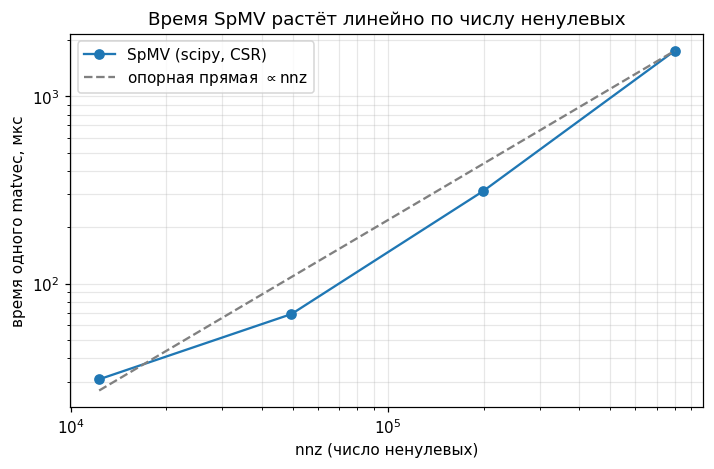

In [6]:
# --- время SpMV растёт линейно по nnz: лог-лог график ---
sizes = (50, 100, 200, 400)
times, nnzs = [], []
for m in sizes:
    n = m * m
    A = grid_laplacian(m)
    x = np.ones(n)
    reps = max(10, int(3e7 / A.nnz))       # больше повторов для малых матриц
    t0 = time.perf_counter()
    for _ in range(reps):
        A @ x
    times.append((time.perf_counter() - t0) / reps)
    nnzs.append(A.nnz)

times = np.array(times)
nnzs = np.array(nnzs)
for m, t, nnz in zip(sizes, times, nnzs):
    print(f'сетка {m:>3}x{m:<3}: nnz = {nnz:>8}, время SpMV = {t * 1e6:8.1f} мкс')

k = times[-1] / nnzs[-1]                   # наклон опорной прямой «время ~ nnz»
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.loglog(nnzs, times * 1e6, 'o-', color='tab:blue', label='SpMV (scipy, CSR)')
ax.loglog(nnzs, k * nnzs * 1e6, '--', color='gray',
          label=r'опорная прямая $\propto \mathrm{nnz}$')
ax.set_xlabel('nnz (число ненулевых)')
ax.set_ylabel('время одного matvec, мкс')
ax.set_title('Время SpMV растёт линейно по числу ненулевых')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
fig.tight_layout()

## 3. 🌊 Sparse Direct Solvers

**Прямые разреженные решатели** — те же методы лекции 11 (Гаусс → LU,
Холецкий), переписанные так, чтобы нули не хранить и не считать. Пайплайн
любого прямого решателя (SuperLU, UMFPACK, MUMPS, Pardiso):

1. **символическая фаза**: по графу матрицы предсказать, где появятся
   ненулевые в $L$ и $U$, и выбрать порядок исключения (об этом — §5);
2. **факторизация** $PAQ = LU$: арифметика только по ненулевым — по строкам
   и столбцам их «настоящей» длины;
3. **решение**: две треугольные прогонки с $L$ и $U$ — по
   $O(\mathrm{nnz}(L))$ и $O(\mathrm{nnz}(U))$ операций (наши $\sim 5n$ у
   прогонки — частный случай).

Главная валюта — **$\mathrm{nnz}(L)$ и $\mathrm{nnz}(U)$**: и память, и
скорость решения определяются тем, насколько хорошо факторизация сохранила
разреженность. Живой пример — двумерное уравнение Пуассона.

In [7]:
# --- 2D-уравнение Пуассона: -Δu = f на сетке 40 x 40, нулевые границы ---
m = 40
n = m * m
h = 1 / (m + 1)
A = (-grid_laplacian(m) / h ** 2).tocsc()          # положительно определённая

i, j = np.meshgrid(np.arange(1, m + 1), np.arange(1, m + 1), indexing='ij')
x_exact = np.sin(np.pi * i * h) * np.sin(2 * np.pi * j * h)   # «точное» решение
b = A @ x_exact.ravel()

t0 = time.perf_counter()
lu = spla.splu(A)                                  # SuperLU: PAQ = LU (порядок COLAMD)
t_factor = time.perf_counter() - t0

t0 = time.perf_counter()
x = lu.solve(b)                                    # две треугольные прогонки
t_solve = time.perf_counter() - t0

res = np.linalg.norm(A @ x - b) / np.linalg.norm(b)
print(f'2D-Пуассон: n = {n} узлов, nnz(A) = {A.nnz}')
print(f'факторизация: {t_factor * 1e3:6.1f} мс | nnz(L) = {lu.L.nnz}, nnz(U) = {lu.U.nnz},'
      f' nnz(L+U) = {lu.L.nnz + lu.U.nnz - n}')
print(f'решение (2 прогонки): {t_solve * 1e3:6.2f} мс | относительная невязка: {res:.2e}')
print(f'столбцовая перестановка COLAMD неединичная: perm_c[:8] = {lu.perm_c[:8]}')

# --- для контраста: та же система плотным методом ---
t0 = time.perf_counter()
xd = np.linalg.solve(A.toarray(), b)
t_dense = time.perf_counter() - t0
print(f'плотный solve той же системы: {t_dense * 1e3:6.0f} мс'
      f' ({t_dense / (t_factor + t_solve):.0f}x дольше),'
      f' память {8 * n * n / 2**20:.0f} МиБ против'
      f' {(12 * (lu.L.nnz + lu.U.nnz) + 8 * n) / 2**20:.1f} МиБ у L+U')

2D-Пуассон: n = 1600 узлов, nnz(A) = 7840
факторизация:    4.9 мс | nnz(L) = 32451, nnz(U) = 32451, nnz(L+U) = 63302
решение (2 прогонки):   0.51 мс | относительная невязка: 2.03e-14
столбцовая перестановка COLAMD неединичная: perm_c[:8] = [956 958 961 965 998 989 921 922]
плотный solve той же системы:    291 мс (54x дольше), память 20 МиБ против 0.8 МиБ у L+U

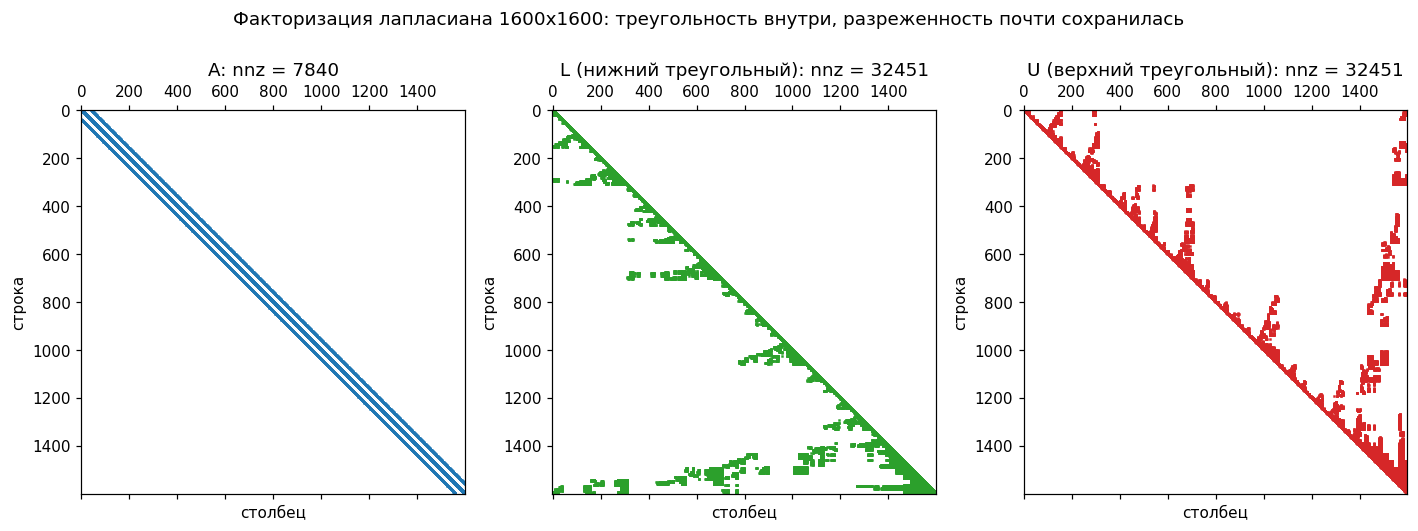

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
ax[0].spy(A, markersize=0.6, color='tab:blue')
ax[0].set_title(f'A: nnz = {A.nnz}')
ax[1].spy(lu.L, markersize=0.6, color='tab:green')
ax[1].set_title(f'L (нижний треугольный): nnz = {lu.L.nnz}')
ax[2].spy(lu.U, markersize=0.6, color='tab:red')
ax[2].set_title(f'U (верхний треугольный): nnz = {lu.U.nnz}')
for a in ax:
    a.set_xlabel('столбец')
    a.set_ylabel('строка')
fig.suptitle(f'Факторизация лапласиана {n}x{n}: треугольность внутри,'
             ' разреженность почти сохранилась', y=1.04)
fig.tight_layout()

## 4. 💥 Fill-in: лавинообразное заполнение нулей

Сравните картинки выше: $\mathrm{nnz}(A) = 7{,}8$ тыс.,
$\mathrm{nnz}(L+U) = 63$ тыс. — при исключении нулей лапласиан «растолстел»
в восемь раз. Новые ненулевые, которых не было в $A$, называются **fill-in**
(заполнением).

Откуда они? На шаге Гаусса мы вычитаем уравнение исключаемой переменной $k$
из уравнений всех её «соседей». Если $a_{ik} \neq 0$ и $a_{kj} \neq 0$, то в
позиции $(i, j)$ рождается элемент. На языке графа:

$$\text{исключили вершину } k \;\Rightarrow\; \text{её соседи попарно связались}$$

— соседей превращают в **клику** (полное подмножество). Каждое новое ребро —
fill-in, а новые рёбра порождают новые.

- **трёхдиагональная матрица** (прогонка!): у исключаемого узла два соседа,
  но они уже связаны — **fill-in $= 0$**. Потому прогонка и стоит $\sim 5n$;
- **звезда** (концентратор + $k$ листьев): исключим концентратор **первым** —
  листья попарно соединятся, $k(k-1)/2$ fill-in, матрица мгновенно гущеет;
  исключим концентратор **последним** — fill-in $= 0$. Матрица одна, порядки
  разные — судьба нулей разная.

In [9]:
def adjacency_sets(A_pattern):
    """Соседство вершин графа матрицы (без диагонали): список множеств."""
    coo = A_pattern.tocoo()
    adj = [set() for _ in range(A_pattern.shape[0])]
    for i, j in zip(coo.row, coo.col):
        if i != j:
            adj[i].add(int(j))
    return adj


def gaussian_fill(A_pattern, order):
    """Учебная симуляция гауссова исключения на графе матрицы.

    order — порядок исключения вершин. Возвращает список fill-пар:
    каждая пара — ребро, которого не было в матрице, но стало после исключения."""
    adj = adjacency_sets(A_pattern)
    fill_pairs = []
    for k in order:
        nb = list(adj[k])
        for a in range(len(nb)):                 # правило клики: все пары
            for b in range(a + 1, len(nb)):      # соседей исключаемой вершины
                u, v = nb[a], nb[b]
                if v not in adj[u]:              # ребра не было -> fill-in
                    fill_pairs.append((u, v))
                    adj[u].add(v)
                    adj[v].add(u)
        for u in nb:                             # вершина k исключена из графа
            adj[u].discard(k)
        adj[k] = set()
    return fill_pairs, adj


print('готово: gaussian_fill(A, order) — симулятор исключения по графу;'
      ' прогоним его на двух «анекдотах» выше')

готово: gaussian_fill(A, order) — симулятор исключения по графу; прогоним его на двух «анекдотах» выше

In [10]:
# --- звезда: центр + 6 листьев. Порядок исключения решает всё ---
k = 6
leaves = np.arange(1, k + 1)
S = sp.coo_matrix((np.ones(2 * k),
                   (np.r_[np.zeros(k, dtype=int), leaves],
                    np.r_[leaves, np.zeros(k, dtype=int)])),
                  shape=(k + 1, k + 1)).tocsr()

fill_first, _ = gaussian_fill(S, np.arange(k + 1))          # центр первым
fill_last, _ = gaussian_fill(S, np.r_[1:k + 1, 0])          # центр последним
print(f'звезда (1 центр + {k} листьев):')
print(f'  центр исключаем ПЕРВЫМ:   fill-in = {len(fill_first):3d} пар — листья стали кликой!')
print(f'  центр исключаем ПОСЛЕДНИМ: fill-in = {len(fill_last):3d} пар — ровно ноль')

# --- трёхдиагональная: прогонка из лекции 11 не создаёт fill-in вовсе ---
Td = sp.diags([np.ones(4), np.ones(4)], [-1, 1], shape=(5, 5)).tocsr()   # паттерн без диагонали
fill_td, _ = gaussian_fill(Td, np.arange(5))
print(f'трёхдиагональная 5x5 (паттерн без диагонали): fill-in = {len(fill_td)}'
      ' — вот откуда ~5n у прогонки')

звезда (1 центр + 6 листьев):
  центр исключаем ПЕРВЫМ:   fill-in =  15 пар — листья стали кликой!
  центр исключаем ПОСЛЕДНИМ: fill-in =   0 пар — ровно ноль
трёхдиагональная 5x5 (паттерн без диагонали): fill-in = 0 — вот откуда ~5n у прогонки

сетка 8x8 (n = 64): nnz(A) = 288, fill-пар = 343, nnz(L+U) ~ 974 (с диагональю)
заполненность: 7.0% до исключения -> 23.8% после (натуральный порядок)

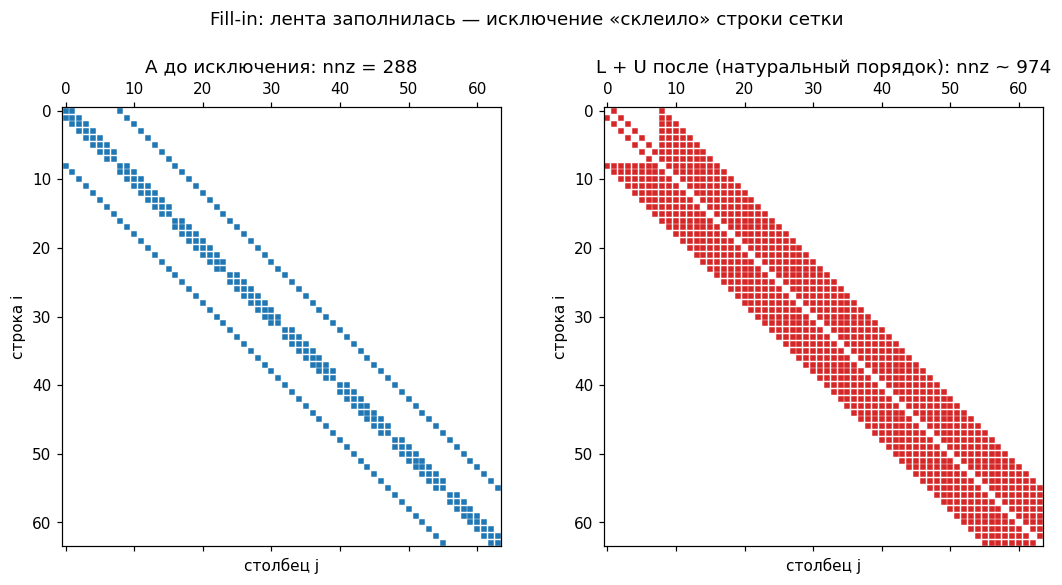

In [11]:
# --- fill-in на настоящей сетке: 8 x 8, натуральный порядок ---
def filled_pattern(A_pattern, fill_pairs):
    """Паттерн L+U после исключения: рёбра исходного графа + fill-пары."""
    N = A_pattern.shape[0]
    coo = A_pattern.tocoo()
    rows, cols = [], []
    for i, j in zip(coo.row, coo.col):
        if i != j:
            rows.append(int(i))
            cols.append(int(j))
    for u, v in fill_pairs:
        rows += [u, v]
        cols += [v, u]
    return sp.coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(N, N)).tocsr()


m = 8
A8 = grid_laplacian(m)
fill_nat, _ = gaussian_fill(A8, np.arange(m * m))
P = filled_pattern(A8, fill_nat)

print(f'сетка 8x8 (n = {m * m}): nnz(A) = {A8.nnz}, fill-пар = {len(fill_nat)},'
      f' nnz(L+U) ~ {P.nnz + m * m} (с диагональю)')
print(f'заполненность: {A8.nnz / m ** 4:.1%} до исключения ->'
      f' {(P.nnz + m * m) / m ** 4:.1%} после (натуральный порядок)')

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].spy(A8, markersize=3, color='tab:blue')
ax[0].set_title(f'A до исключения: nnz = {A8.nnz}')
ax[1].spy(P, markersize=3, color='tab:red')
ax[1].set_title(f'L + U после (натуральный порядок): nnz ~ {P.nnz + m * m}')
for a in ax:
    a.set_xlabel('столбец j')
    a.set_ylabel('строка i')
fig.suptitle('Fill-in: лента заполнилась — исключение «склеило» строки сетки', y=1.02)
fig.tight_layout()

## 5. 🔀 Переупорядочивания: порядок исключения как ресурс

Fill-in — не свойство матрицы, а свойство **порядка исключения**. Вместо
$Ax=b$ можно решать эквивалентную систему с перенумерованными неизвестными:

$$(PAP^\top)\,y = Pb, \qquad x = P^\top y,$$

— решение то же, но граф $PAP^\top$ — это тот же граф с перенумерованными
вершинами, и исключаться он может совсем иначе. Алгоритм исключения не
меняется — меняется расстановка фигур. Три классических стратегии:

- **RCM** (обратный алгоритм Катхилла–Макки) — стянуть матрицу в узкую ленту;
- **minimum degree / AMD** — жадно исключать вершины минимальной степени;
- **nested dissection** — рекурсивно вырезать сечения-разделители.

### 5.1 RCM: стянуть в ленту

Алгоритм Катхилла–Макки — обход графа в ширину от периферийной вершины:
вершины нумеруются по «уровням» удалённости, соседи получают близкие номера —
ненулевые собираются около диагонали, ширина ленты $w$ мала. «Обратный»
вариант (RCM) разворачивает нумерацию: лента та же, но профиль (число
ненулевых в треугольнике) меньше — именно это и нужно исключению.

Для ленточной матрицы с шириной $w$ факторизация стоит $\sim n w^2$ операций
и $\sim n w$ памяти: у трёхдиагональной ($w = 3$) это наши $\sim 5n$, у 2D-
сетки с $w = m$ — уже $n^{3/2}$.

Проверим на вытянутой сетке $4 \times 60$: в натуральном порядке «строка за
строкой» сосед по вертикали отстоит на $60$ номеров — лента шириной $60$.
RCM найдёт порядок с полосой шириной $5$.

сетка 4 x 60: nnz = 1072
натуральный порядок: ширина ленты = 60
RCM:                 ширина ленты = 5

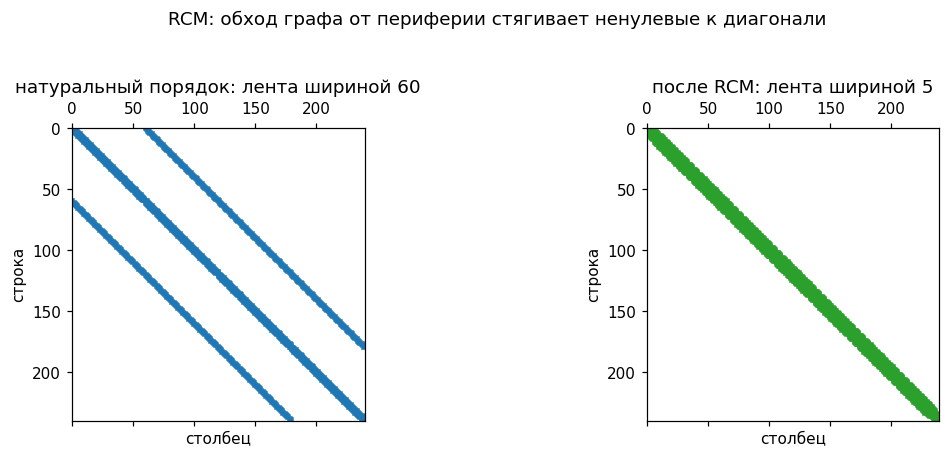

In [12]:
# --- вытянутая сетка 4 x 60: натуральный порядок даёт ленту шириной 60 ---
h_len = 60
T_long = sp.diags([np.ones(h_len - 1), -2 * np.ones(h_len), np.ones(h_len - 1)],
                  [-1, 0, 1], shape=(h_len, h_len))
T_short = sp.diags([np.ones(3), -2 * np.ones(4), np.ones(3)], [-1, 0, 1], shape=(4, 4))
S = (sp.kron(sp.eye(4), T_long) + sp.kron(T_short, sp.eye(h_len))).tocsr()


def bandwidth(M):
    """Ширина ленты: максимальное |i - j| среди ненулевых."""
    i, j = M.nonzero()
    return int(np.abs(i - j).max())


perm = reverse_cuthill_mckee(S, symmetric_mode=True)
S_rcm = S[perm][:, perm].tocsr()

print(f'сетка 4 x 60: nnz = {S.nnz}')
print(f'натуральный порядок: ширина ленты = {bandwidth(S)}')
print(f'RCM:                 ширина ленты = {bandwidth(S_rcm)}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].spy(S, markersize=2, color='tab:blue')
ax[0].set_title(f'натуральный порядок: лента шириной {bandwidth(S)}')
ax[1].spy(S_rcm, markersize=2, color='tab:green')
ax[1].set_title(f'после RCM: лента шириной {bandwidth(S_rcm)}')
for a in ax:
    a.set_xlabel('столбец')
    a.set_ylabel('строка')
fig.suptitle('RCM: обход графа от периферии стягивает ненулевые к диагонали', y=1.03)
fig.tight_layout()

### 5.2 Minimum degree и AMD: исключай самого «лёгкого»

Идея жадного минимума: на каждом шаге исключать вершину с **минимальной
текущей степенью** (числом ненулевых в её строке) — она порождает меньше
всего fill-in. Это точный алгоритм **minimum degree (MD)**; знаменитый
**AMD** (Approximate Minimum Degree, Amestoy–Davis–Duff) — его быстрый
аппроксимированный вариант: вместо точных степеней считаются «внешние»
степени по сжатому графу, зато AMD работает на миллионах вершин. В SuperLU
по умолчанию применяется родственный **COLAMD** — столбцовый приближённый
minimum degree (мы видели его перестановку `perm_c` в §3).

In [13]:
def minimum_degree_order(A_pattern):
    """Жадный minimum degree: каждый шаг исключаем вершину с минимальной степенью."""
    adj = adjacency_sets(A_pattern)
    remaining = set(range(A_pattern.shape[0]))
    order = []
    while remaining:
        k = min(remaining, key=lambda v: len(adj[v]))
        remaining.discard(k)
        order.append(k)
        nb = list(adj[k])
        for a in range(len(nb)):                 # правило клики — как в gaussian_fill
            for b in range(a + 1, len(nb)):
                u, v = nb[a], nb[b]
                if v not in adj[u]:
                    adj[u].add(v)
                    adj[v].add(u)
        for u in nb:
            adj[u].discard(k)
        adj[k] = set()
    return np.array(order)


m = 24
A24 = grid_laplacian(m)
n24 = m * m

fill_nat, _ = gaussian_fill(A24, np.arange(n24))
fill_rcm, _ = gaussian_fill(A24, reverse_cuthill_mckee(A24, symmetric_mode=True))
fill_md, _ = gaussian_fill(A24, minimum_degree_order(A24))

print(f'сетка 24x24 (n = {n24}): fill-пар при исключении')
print(f'  натуральный порядок:  {len(fill_nat):6d}')
print(f'  RCM:                  {len(fill_rcm):6d}  ({len(fill_rcm) / len(fill_nat):.2f} от натурального)')
print(f'  minimum degree:       {len(fill_md):6d}  ({len(fill_md) / len(fill_nat):.2f} от натурального)')
print('жадный минимум на средних сетках обычно обыгрывает и натуральный порядок, и RCM')

сетка 24x24 (n = 576): fill-пар при исключении
  натуральный порядок:   12167
  RCM:                    8372  (0.69 от натурального)
  minimum degree:         4435  (0.36 от натурального)
жадный минимум на средних сетках обычно обыгрывает и натуральный порядок, и RCM

### 5.3 Nested Dissection: разделяй и властвуй

Самая красивая стратегия. Разрежем область **сечением** — тонкой полосой
узлов, убрав которую, область распадётся на две независимые половины.
Сечение исключаем **последним** (в момент его исключения половины уже
обработаны и «не мешают»), а с половинами поступаем рекурсивно — снова
половинки и сечения, пока не дойдём до отдельных узлов:

$$\text{порядок} = \text{(левая половина)} \to \text{(правая половина)} \to \text{(сечение)}$$

Пока живы половины, сечение связывает только две «стенки» — fill-in локален.
Итог для 2D-сетки доказан Джорджем и Лю: факторизация стоит
$O(n^{3/2})$ операций при памяти $O(n \log n)$; в 3D — $O(n^2)$ операций и
$O(n^{4/3})$ памяти. Против $n^3/3$ и $O(n^2)$ плотного Гаусса — победа на
порядки, причём **доказанная**, а не эмпирическая.

сетка 16x16: сечений уровня 1 — 16, уровня 2 — 15, всего уровней 6
fill-пар: натуральный 3375 -> nested dissection 1927 (0.57x)

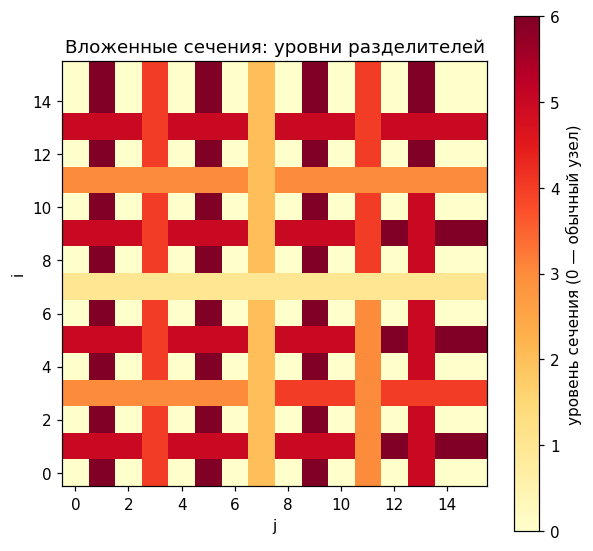

In [14]:
def nested_dissection_order(m):
    """ND-порядок для m x m сетки: рекурсивное деление, сечение — в конец."""
    def rec(cells):
        if len(cells) <= 2:
            return list(cells)
        i0, i1 = min(c[0] for c in cells), max(c[0] for c in cells)
        j0, j1 = min(c[1] for c in cells), max(c[1] for c in cells)
        if i1 - i0 >= j1 - j0:                   # делим по более длинной стороне
            axis, mid = 0, (i0 + i1) // 2
        else:
            axis, mid = 1, (j0 + j1) // 2
        left = [c for c in cells if c[axis] < mid]
        sep = [c for c in cells if c[axis] == mid]
        right = [c for c in cells if c[axis] > mid]
        if not left or not right:
            return list(cells)
        return rec(left) + rec(right) + sep      # половины — сначала, сечение — в конец

    cells = [(i, j) for i in range(m) for j in range(m)]
    return np.array([i * m + j for (i, j) in rec(cells)])


def nd_levels(m):
    """Карта уровней сечений: 0 — обычный узел, k — узел сечения уровня k."""
    levels = np.zeros((m, m), dtype=int)

    def rec(cells, level):
        if len(cells) <= 2:
            return
        i0, i1 = min(c[0] for c in cells), max(c[0] for c in cells)
        j0, j1 = min(c[1] for c in cells), max(c[1] for c in cells)
        if i1 - i0 >= j1 - j0:
            axis, mid = 0, (i0 + i1) // 2
        else:
            axis, mid = 1, (j0 + j1) // 2
        left = [c for c in cells if c[axis] < mid]
        sep = [c for c in cells if c[axis] == mid]
        right = [c for c in cells if c[axis] > mid]
        if not left or not right:
            return
        for (i, j) in sep:
            levels[i, j] = level
        rec(left, level + 1)
        rec(right, level + 1)

    rec([(i, j) for i in range(m) for j in range(m)], 1)
    return levels


m = 16
lv = nd_levels(m)
fill_nd16, _ = gaussian_fill(grid_laplacian(m), nested_dissection_order(m))
fill_nat16, _ = gaussian_fill(grid_laplacian(m), np.arange(m * m))

print(f'сетка 16x16: сечений уровня 1 — {(lv == 1).sum()}, уровня 2 — {(lv == 2).sum()},'
      f' всего уровней {lv.max()}')
print(f'fill-пар: натуральный {len(fill_nat16)} -> nested dissection {len(fill_nd16)}'
      f' ({len(fill_nd16) / len(fill_nat16):.2f}x)')

fig, ax = plt.subplots(figsize=(5.6, 5.2))
im = ax.imshow(lv, cmap='YlOrRd', origin='lower')
ax.set_title('Вложенные сечения: уровни разделителей')
ax.set_xlabel('j')
ax.set_ylabel('i')
fig.colorbar(im, ax=ax, label='уровень сечения (0 — обычный узел)')
fig.tight_layout()

### 5.4 Все порядки на одной арене

Одна и та же сетка $24 \times 24$, один и тот же алгоритм исключения —
четыре разных порядка.

сетка 24x24 (n = 576, nnz(A) = 2784):
           порядок |  fill-пар |  nnz(L+U) | к натуральному
       натуральный |     12167 |     27118 |          1.00x
               RCM |      8372 |     19528 |          0.69x
    minimum degree |      4435 |     11654 |          0.36x
 nested dissection |      5952 |     14688 |          0.49x

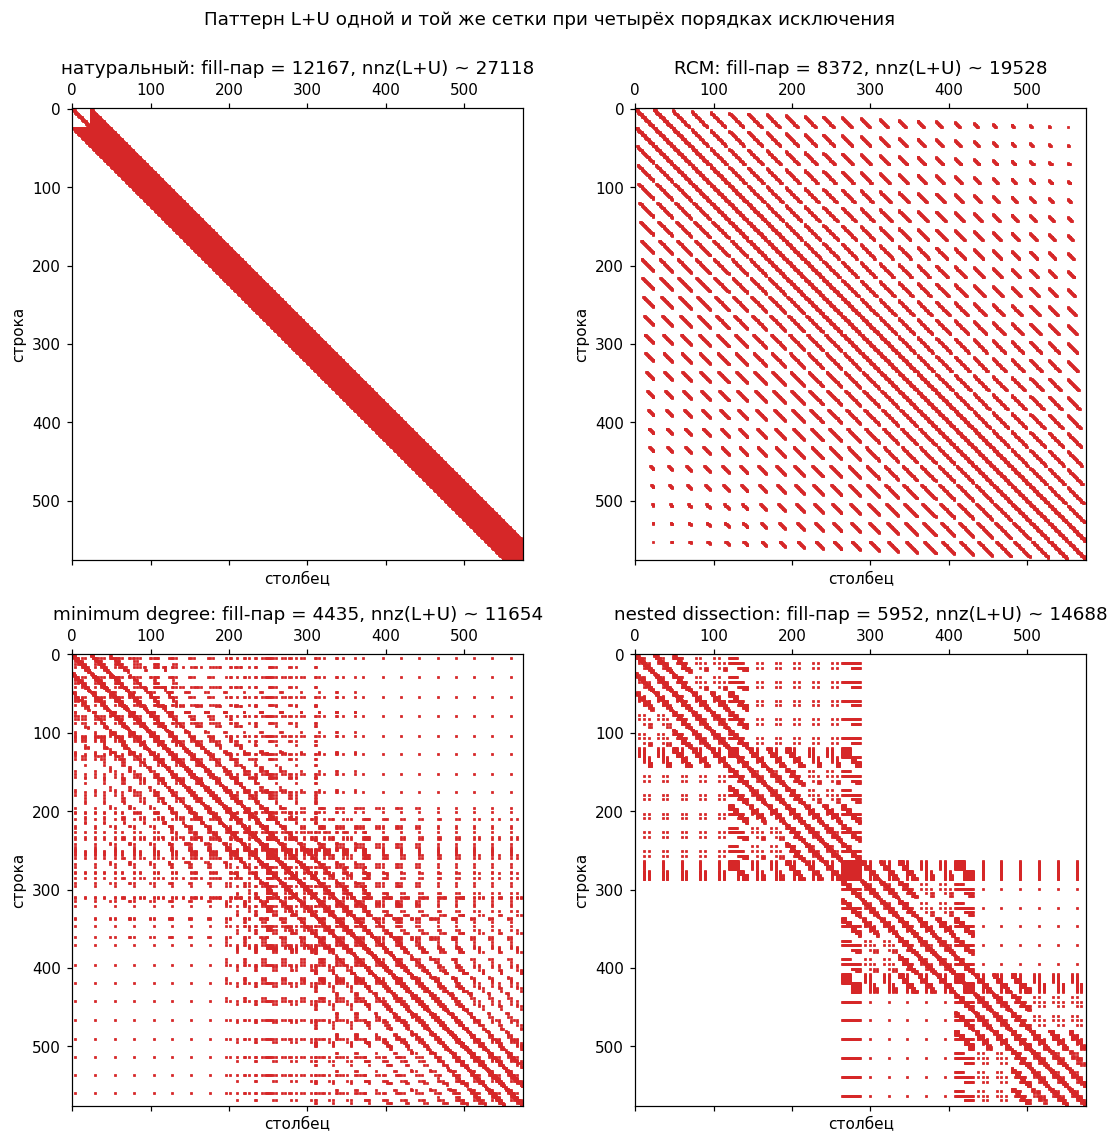

In [15]:
m = 24
A24 = grid_laplacian(m)
n24 = m * m

orders = [('натуральный', np.arange(n24)),
          ('RCM', reverse_cuthill_mckee(A24, symmetric_mode=True)),
          ('minimum degree', minimum_degree_order(A24)),
          ('nested dissection', nested_dissection_order(m))]

fill_ref, _ = gaussian_fill(A24, np.arange(n24))
print(f'сетка 24x24 (n = {n24}, nnz(A) = {A24.nnz}):')
print(f'{"порядок":>18} | {"fill-пар":>9} | {"nnz(L+U)":>9} | {"к натуральному":>14}')
for name, order in orders:
    fp, _ = gaussian_fill(A24, order)
    P = filled_pattern(A24, fp)
    print(f'{name:>18} | {len(fp):>9} | {P.nnz + n24:>9} | {len(fp) / len(fill_ref):>13.2f}x')

fig, ax = plt.subplots(2, 2, figsize=(10.4, 10.4))
for a, (name, order) in zip(ax.ravel(), orders):
    fp, _ = gaussian_fill(A24, order)
    P = filled_pattern(A24, fp)
    a.spy(P, markersize=0.8, color='tab:red')
    a.set_title(f'{name}: fill-пар = {len(fp)}, nnz(L+U) ~ {P.nnz + n24}')
    a.set_xlabel('столбец')
    a.set_ylabel('строка')
fig.suptitle('Паттерн L+U одной и той же сетки при четырёх порядках исключения', y=0.995)
fig.tight_layout()

     n |       натуральный |               RCM |    minimum degree | nested dissection
    64 |               343 |               252 |               183 |               245
   144 |              1331 |               946 |               618 |               826
   256 |              3375 |              2360 |              1443 |              1927
   576 |             12167 |              8372 |              4435 |              5952
  1024 |             29791 |             20336 |              9324 |             12845

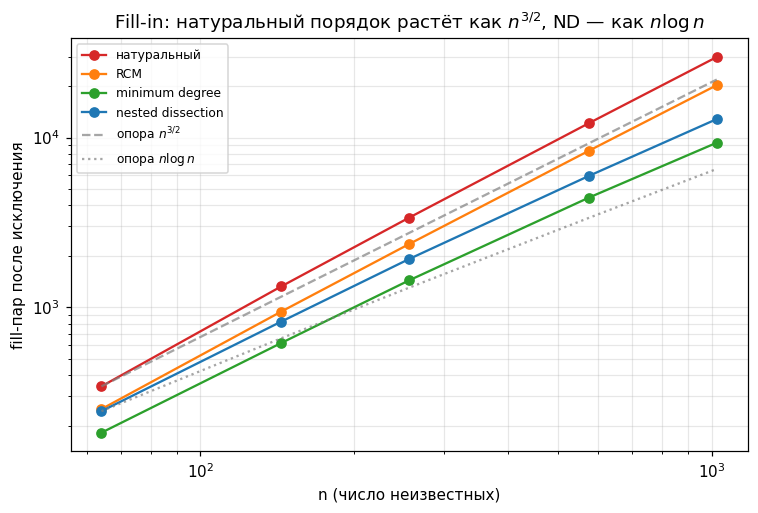

In [16]:
# --- масштабирование fill-in: n против числа fill-пар (лог-лог) ---
sizes = (8, 12, 16, 24, 32)
fills = {'натуральный': [], 'RCM': [], 'minimum degree': [], 'nested dissection': []}
for mm in sizes:
    Ag = grid_laplacian(mm)
    nn = mm * mm
    fills['натуральный'].append(len(gaussian_fill(Ag, np.arange(nn))[0]))
    fills['RCM'].append(len(gaussian_fill(Ag, reverse_cuthill_mckee(Ag, symmetric_mode=True))[0]))
    fills['minimum degree'].append(len(gaussian_fill(Ag, minimum_degree_order(Ag))[0]))
    fills['nested dissection'].append(len(gaussian_fill(Ag, nested_dissection_order(mm))[0]))

ns = np.array([mm * mm for mm in sizes], dtype=float)
print(f'{"n":>6} | ' + ' | '.join(f'{name:>17}' for name in fills))
for nn, *vals in zip(ns, *fills.values()):
    print(f'{nn:>6.0f} | ' + ' | '.join(f'{v:>17.0f}' for v in vals))

colors = {'натуральный': 'tab:red', 'RCM': 'tab:orange',
          'minimum degree': 'tab:green', 'nested dissection': 'tab:blue'}
fig, ax = plt.subplots(figsize=(7, 4.8))
for name, vals in fills.items():
    ax.loglog(ns, vals, 'o-', color=colors[name], label=name)
ax.loglog(ns, fills['натуральный'][0] / ns[0] ** 1.5 * ns ** 1.5, '--', color='gray',
          alpha=0.7, label=r'опора $n^{3/2}$')
ax.loglog(ns, fills['nested dissection'][0] / (ns[0] * np.log2(ns[0])) * ns * np.log2(ns),
          ':', color='gray', alpha=0.7, label=r'опора $n\log n$')
ax.set_xlabel('n (число неизвестных)')
ax.set_ylabel('fill-пар после исключения')
ax.set_title('Fill-in: натуральный порядок растёт как $n^{3/2}$, ND — как $n\\log n$')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

In [17]:
# --- и это не теория: тот же эффект внутри реального решателя SuperLU ---
m = 60
n = m * m
A = (-grid_laplacian(m)).tocsc()
rng = np.random.default_rng(0)
b = A @ rng.random(n)

print(f'сетка 60x60: n = {n}, nnz(A) = {A.nnz} — меняем ТОЛЬКО порядок исключения:')
for spec in ('NATURAL', 'MMD_AT_PLUS_A', 'COLAMD'):
    t0 = time.perf_counter()
    lu = spla.splu(A, permc_spec=spec)
    t_factor = time.perf_counter() - t0
    t0 = time.perf_counter()
    x = lu.solve(b)
    t_solve = time.perf_counter() - t0
    nnz_lu = lu.L.nnz + lu.U.nnz - n
    res = np.linalg.norm(A @ x - b) / np.linalg.norm(b)
    print(f'  {spec:>14}: nnz(L+U) = {nnz_lu:7d} | факторизация {t_factor * 1e3:6.1f} мс |'
          f' прогонки {t_solve * 1e6:6.0f} мкс | невязка {res:.1e}')

print('NATURAL — без переупорядочивания: память и время растут вместе с fill-in;')
print('MMD/COLAMD (minimum degree) срезают и то, и другое. Решение то же — невязка машинная.')

сетка 60x60: n = 3600, nnz(A) = 17760 — меняем ТОЛЬКО порядок исключения:
         NATURAL: nnz(L+U) =  428518 | факторизация   42.1 мс | прогонки   1431 мкс | невязка 7.6e-16
   MMD_AT_PLUS_A: nnz(L+U) =  104830 | факторизация   17.2 мс | прогонки    636 мкс | невязка 2.3e-16
          COLAMD: nnz(L+U) =  176120 | факторизация   14.8 мс | прогонки   1128 мкс | невязка 3.0e-16
NATURAL — без переупорядочивания: память и время растут вместе с fill-in;
MMD/COLAMD (minimum degree) срезают и то, и другое. Решение то же — невязка машинная.

## 6. 🧭 Итоги

**Что узнали.**

1. Крупные СЛАУ почти всегда **разрежены**: шаблон схемы мал, матрица —
   граф задачи. Плотное хранение $O(n^2)$ байт — путь в никуда: для сетки
   $1000 \times 1000$ это 8 ТБ против 60 МБ у CSR.
2. **COO** — список троек «значение–строка–столбец»: удобна для сборки,
   дубликаты суммируются; **CSR** — сжатые строки: главный рабочий формат
   (SpMV за $O(\mathrm{nnz})$); **CSC** — сжатые столбцы: столбцовые
   операции и факторизация.
3. SpMV — рабочая операция разреженной алгебры: время линейно по nnz,
   нули не читаются; на сетке $64 \times 64$ плотный matvec медленнее в
   сотни раз.
4. **Sparse direct solvers** — Гаусс/LU с пропуском нулей: символическая
   фаза (предсказать структуру $L$ и $U$, выбрать порядок) + численная
   факторизация + две треугольные прогонки по $O(\mathrm{nnz}(L+U))$.
5. **Fill-in**: исключение вершины склеивает её соседей в клику — нули
   заполняются лавинообразно. Прогонка — счастливый нулевой fill-in
   ($\sim 5n$); звезда с неудачным первым ходом — $k(k-1)/2$ новых рёбер.
6. Fill-in — свойство **порядка исключения**, а не матрицы: $PAP^\top$ —
   та же задача, другая судьба нулей.
7. **RCM** стягивает матрицу в ленту (60 → 5 на сетке $4 \times 60$);
   **minimum degree (AMD)** жадно исключает самые «лёгкие» вершины — лучший
   практический выбор на средних задачах; **nested dissection** рекурсивно
   вырезает сечения — доказуемо $O(n^{3/2})$ работы и $O(n \log n)$ памяти
   в 2D ($O(n^2)$ и $O(n^{4/3})$ в 3D).
8. На реальном SuperLU (сетка $60 \times 60$) переупорядочивание даёт
   $\times 2$–$\times 4$ экономию памяти и $\times 4$–$\times 5$ ускорение
   факторизации (NATURAL против MMD/COLAMD) при машинной невязке.

**Арифметическая сложность и память:**

| метод | работа | память | комментарий |
|---|---|---|---|
| плотный Гаусс (лекция 11) | $n^3/3$ | $O(n^2)$ | нули не пропускает |
| прогонка (лекция 11) | $\sim 5n$ | $O(n)$ | трёхдиагональная, fill-in $=0$ |
| SpMV | $O(\mathrm{nnz})$ | $O(\mathrm{nnz})$ | рабочая операция итераций |
| sparse direct, 2D + ND | $O(n^{3/2})$ | $O(n \log n)$ | сеточные задачи |
| sparse direct, 3D + ND | $O(n^2)$ | $O(n^{4/3})$ | заметно дороже, но всё равно выигрыш |

Для сетки $1000 \times 1000$ ($n = 10^6$): плотному Гауссу нужно
$\sim 3\cdot 10^{17}$ операций и 8 ТБ памяти; ND-упорядоченному разреженному
решателю — порядка $10^{10}$–$10^{11}$ операций и сотни мегабайт. Ответ на
вопрос лекции: **терабайты рождаются из fill-in при неудачном порядке**, а
сжатые форматы хранения плюс правильный порядок (AMD, nested dissection)
превращают невозможную задачу в рутинную.

**Куда это пойдёт.**

- **итерационные методы** (следующие лекции): Якоби, Гаусса–Зейделя,
  сопряжённые градиенты, GMRES — для 3D-задач даже $O(n^2)$ прямого
  решателя дорого, и главным инструментом станет именно SpMV;
- **предобусловливание**: неполные факторизации ILU — «обрезанный»
  разреженный LU из этой лекции — работают как предобусловливатель;
- **параллельные прямые решатели** (MUMPS, SuperLU_DIST): вложенные
  сечения ценны ещё и тем, что половинки исключаются независимо;
- **графовая комбинаторика**: минимизация полосы, поиск разделителей —
  целая индустрия внутри высокопроизводительных вычислений.

**Практика (своими руками):**

- соберите матрицу пятиточечного шаблона для сетки $3000 \times 3000$ и
  посчитайте память CSR против плотной; сверьте формулу
  $8\,\mathrm{nnz} + 4\,\mathrm{nnz} + 4\,(n+1)$ с `A.data.nbytes`,
  `A.indices.nbytes`, `A.indptr.nbytes`;
- соберите COO с повторяющимися координатами (модель МКЭ: четыре элемента
  «вкладываются» в один узел) и убедитесь, что конверсия в CSR их суммирует;
- запустите `gaussian_fill` для звезды из 12 листьев: центр первым — 66
  fill-пар, центр последним — 0; придумайте граф, при котором плохи оба
  порядка;
- сравните `permc_spec` на сетке $80 \times 80$: найдите порядок с
  минимальным `nnz(L+U)` и проверьте невязку;
- реализуйте ND для прямоугольника $2m \times m$ и сравните fill-in с
  натуральным порядком; заодно объясните, почему RCM здесь почти идеален.